In [131]:
import os
from dotenv import load_dotenv
load_dotenv()

api_key = os.getenv("GROQ_API_KEY")

Necessary Libraries for our project

In [132]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model    
from langchain.tools import tool 
from pydantic import BaseModel, Field
from langchain.agents.structured_output import ToolStrategy



Setting up model

In [ ]:
model = init_chat_model(model="qwen/qwen3.8-27b",model_provider="groq")
#model = init_chat_model( model="openai/gpt-oss-120b", model_provider="groq")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.7', 'langchain': '1.4.9'}}, client=<groq.resources.chat.completions.Completions object at 0x0000023E6548E430>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000023E66488210>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

Creating tools fro LLM reference

In [134]:
@tool
def track_expense(amount: float, category: dict) -> str:
    """
    Track an expense with the given amount, and category. Category can be one of the following: Food, Transportation, Entertainment, Utilities, or Other.
    """
    # Here you would implement the logic to track the expense
    return f"Tracked expense of rupees {amount} for {category}"

In [135]:
@tool
def get_expense_report() -> str:
    """
    Get a report of all tracked expenses.
    """
    # Here you would implement the logic to generate the expense report
    return "Expense report: ..."

Setting output structure for our report

In [136]:
class ExpenseTrackerReport(BaseModel):
    total_expenses: float = Field(default=0.0, description="Total amount of expenses tracked.")
    categories: dict = Field(description="A dictionary to track expenses by category.")
    advice: str = Field(description="Advice based on spending habits.")



Creating agent for my expense tracker

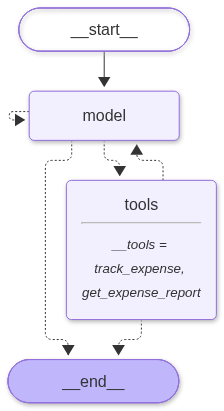

In [137]:
agent = create_agent(
    model=model,
    tools=[track_expense, get_expense_report],
    response_format=ToolStrategy(ExpenseTrackerReport),
    system_prompt=(
        "You are a personal finance assistant. "
        "For every expense the user mentions, call track_expense. "
        "Then call get_expense_report and use its result "
        "to fill the final report with brief advice."
    )
)

agent

Generating my report

In [138]:
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "I spent 500 rupees on food and 1000 rupees on transportation today."}
    ]
})

In [139]:
response

{'messages': [HumanMessage(content='I spent 500 rupees on food and 1000 rupees on transportation today.', additional_kwargs={}, response_metadata={}, id='fde09f29-5e21-48ce-b4e7-9bd350ebbded'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'b00ja86ma', 'function': {'arguments': '{"amount":500,"category":{"category_name":"Food"}}', 'name': 'track_expense'}, 'type': 'function'}, {'id': 'k1zmqjbzg', 'function': {'arguments': '{"amount":1000,"category":{"category_name":"Transportation"}}', 'name': 'track_expense'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 98, 'prompt_tokens': 540, 'total_tokens': 638, 'completion_time': 0.192406283, 'completion_tokens_details': None, 'prompt_time': 0.037108925, 'prompt_tokens_details': None, 'queue_time': 0.073861921, 'total_time': 0.229515208}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model

In [140]:
response["structured_response"].model_dump()

{'total_expenses': 1500.0,
 'categories': {'Food': 500, 'Transportation': 1000},
 'advice': 'Your spending is currently weighted toward transportation (2/3 of total). Consider planning shared rides, public transit, or batching errands to reduce travel costs. Food spending looks reasonable; you could further optimize by meal-prepping to avoid costly convenience meals.'}